# 03 — Train and evaluate

A station/month/hour climatology shrunk toward global training prevalence is
the baseline. The model comparison uses 2017–2022 for training, Jan–Jun 2023 for selection,
Jul–Dec 2023 for optional probability calibration, and 2024 as the final holdout.
The selection policy ranks mean PR-AUC over supported thresholds, uses Brier score
to break close ties, and reports F1 at a fixed 0.5 reference cutoff. No cutoff is
optimized. Run the final evaluation cell only after the selection and calibration
cells have completed.

The selection table compares climatology, LR-A, LR-B, RF-B, GBT-A, and GBT-B.
The 2024 comparison contains only climatology and the frozen winner; if
calibration is enabled, the winner is scored with calibrated probabilities.


In [1]:
import json
import math
import os
import subprocess
import tempfile
from decimal import Decimal
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display
from pyspark import StorageLevel
from pyspark.ml import Pipeline
from pyspark.ml.classification import (
    GBTClassifier,
    LogisticRegression,
    RandomForestClassifier,
)
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import Imputer, OneHotEncoder, StandardScaler, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.regression import IsotonicRegression
from pyspark.sql import SparkSession, Window, functions as F


In [2]:
BUCKET = os.environ.get("BUCKET", "sg-rainfall-dsa5208-261011-data")
RUN_ID = os.environ.get("RUN_ID", "20261012-full-02")
ROOT = f"gs://{BUCKET}/runs/{RUN_ID}"
MODEL_ROOT = f"{ROOT}/models"
RESULTS_ROOT = f"{ROOT}/results"
config_result = subprocess.run(
    ["gcloud", "storage", "cat", f"{ROOT}/config/experiment.json"],
    check=True, capture_output=True, text=True,
)
config = json.loads(config_result.stdout)

spark = SparkSession.builder.appName("dsa5208-rainfall-models").getOrCreate()
spark.conf.set("spark.sql.shuffle.partitions", str(config["shuffle_partitions"]))
spark.conf.set("spark.sql.session.timeZone", config["timezone"])
spark.conf.set("spark.sql.ansi.enabled", "false")
actual_spark_conf = {
    name: spark.conf.get(name)
    for name in ("spark.sql.shuffle.partitions", "spark.sql.session.timeZone", "spark.sql.ansi.enabled")
}
assert actual_spark_conf["spark.sql.shuffle.partitions"] == str(config["shuffle_partitions"])
assert actual_spark_conf["spark.sql.session.timeZone"] == config["timezone"]
assert actual_spark_conf["spark.sql.ansi.enabled"] == "false"
display({"actual_spark_conf": actual_spark_conf})

assert config["availability_mode"] == "retrospective_event_time"
assert config["alignment_tolerance_seconds"] == 0
assert config["interval_semantics_confirmed"] or config["interval_end_assumption_accepted"]


26/10/12 10:21:02 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


{'actual_spark_conf': {'spark.sql.shuffle.partitions': '64',
  'spark.sql.session.timeZone': 'Asia/Singapore',
  'spark.sql.ansi.enabled': 'false'}}

In [3]:
BASE_FEATURES = ["hour_sin", "hour_cos", "day_sin", "day_cos", "threshold_mm"]

def feature_columns(variant):
    if variant == "A":
        return list(BASE_FEATURES)
    if variant != "B":
        raise ValueError("Feature variant must be A or B.")
    columns = BASE_FEATURES + ["rain_current"]
    for minutes in config["lag_minutes"]:
        columns += [f"lag_{minutes}", f"lag_{minutes}_missing"]
    for minutes in config["rolling_minutes"]:
        columns += [
            f"sum_{minutes}", f"max_{minutes}", f"wet_count_{minutes}",
            f"count_{minutes}", f"coverage_{minutes}",
        ]
    return columns


In [4]:
def threshold_units(value):
    scaled = Decimal(str(value)) * config["rainfall_integer_scale"]
    if scaled != scaled.to_integral_value():
        raise ValueError(f"Threshold {value} exceeds the stored numeric precision.")
    return int(scaled)

def expand_thresholds(frame, thresholds=None):
    values = thresholds or config["thresholds_mm"]
    rows = [(float(value), threshold_units(value)) for value in values]
    grid = spark.createDataFrame(rows, "threshold_mm double, threshold_units long")
    expanded = frame.crossJoin(F.broadcast(grid))
    return expanded.withColumn(
        "label", (F.col("future_units") > F.col("threshold_units")).cast("double")
    )


In [5]:
def deterministic_sample(frame, fraction):
    if fraction >= 1:
        return frame
    bucket = F.pmod(
        F.xxhash64("station_id", "epoch", F.lit(config["sampling_seed"])),
        F.lit(1_000_000),
    )
    return frame.where(bucket < int(fraction * 1_000_000))

def mark_unseen(frame, seen_stations):
    return (
        frame.join(seen_stations.withColumn("_seen", F.lit(True)), "station_id", "left")
        .withColumn("unseen_station", F.col("_seen").isNull())
        .drop("_seen")
    )


In [6]:
base = spark.read.parquet(f"{ROOT}/base_features")
train_base = base.where("split = 'train' AND label_valid")
selection_base = base.where("split = 'selection' AND label_valid")
calibration_base = base.where("split = 'calibration' AND label_valid")

for name, frame in [
    ("train", train_base),
    ("selection", selection_base),
    ("calibration", calibration_base),
]:
    if frame.limit(1).count() == 0:
        raise ValueError(f"The {name} split has no valid six-reading targets.")


In [7]:
training_stations = train_base.select("station_id").distinct().persist()
threshold_values = config["thresholds_mm"]
support_counts = train_base.agg(
    F.count("*").alias("n"),
    *[
        F.sum(
            (F.col("future_units") > F.lit(threshold_units(value))).cast("long")
        ).alias(f"positive_{index}")
        for index, value in enumerate(threshold_values)
    ],
).first().asDict()
support = [
    {
        "threshold_mm": float(value),
        "n": int(support_counts["n"]),
        "positives": int(support_counts[f"positive_{index}"] or 0),
    }
    for index, value in enumerate(threshold_values)
]
primary_thresholds = sorted(
    row["threshold_mm"]
    for row in support
    if config["primary_threshold_min_positives"] <= row["positives"] < row["n"]
)
if not primary_thresholds:
    raise ValueError("No threshold has sufficient positive and negative training support.")
display(support)


26/10/12 10:21:15 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


[{'threshold_mm': 0.2, 'n': 34542285, 'positives': 1515802},
 {'threshold_mm': 0.5, 'n': 34542285, 'positives': 1160284},
 {'threshold_mm': 1.0, 'n': 34542285, 'positives': 804747},
 {'threshold_mm': 2.0, 'n': 34542285, 'positives': 535577},
 {'threshold_mm': 5.0, 'n': 34542285, 'positives': 279801},
 {'threshold_mm': 10.0, 'n': 34542285, 'positives': 134448}]

In [8]:
pilot = expand_thresholds(
    deterministic_sample(train_base, config["pilot_fraction"])
).persist(StorageLevel.DISK_ONLY)
train = expand_thresholds(
    deterministic_sample(train_base, config["final_train_fraction"])
).persist(StorageLevel.DISK_ONLY)
selection = mark_unseen(expand_thresholds(selection_base), training_stations).persist(
    StorageLevel.DISK_ONLY
)


26/10/12 10:21:21 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.
26/10/12 10:21:21 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


26/10/12 10:21:21 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


26/10/12 10:21:21 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


In [9]:
def histogram(keys):
    return (
        train_base.groupBy(*keys, "future_units")
        .count()
        .withColumnRenamed("count", "frequency")
    )

station_hist = histogram(["station_id", "month", "hour"])
month_hist = histogram(["month", "hour"])
global_hist = histogram([])
climatology_root = f"{MODEL_ROOT}/climatology"
station_hist.write.mode("overwrite").parquet(f"{climatology_root}/station_hour")
month_hist.write.mode("overwrite").parquet(f"{climatology_root}/month_hour")
global_hist.write.mode("overwrite").parquet(f"{climatology_root}/global")

display({
    "pilot_base_rows": pilot.select("station_id", "epoch").distinct().count(),
    "final_train_base_rows": train.select("station_id", "epoch").distinct().count(),
    "selection_rows_after_threshold_expansion": selection.count(),
    "primary_thresholds_mm": primary_thresholds,
})


{'pilot_base_rows': 173478,
 'final_train_base_rows': 690699,
 'selection_rows_after_threshold_expansion': 19952994,
 'primary_thresholds_mm': [0.2, 0.5, 1.0, 2.0, 5.0, 10.0]}

In [10]:
def global_climatology_probability(query):
    threshold_grid = query.select("threshold_mm", "threshold_units").distinct()
    return (
        threshold_grid.crossJoin(global_hist)
        .groupBy("threshold_mm", "threshold_units")
        .agg(
            F.sum("frequency").alias("global_n"),
            F.sum(
                F.when(
                    F.col("future_units") > F.col("threshold_units"),
                    F.col("frequency"),
                ).otherwise(0)
            ).alias("global_positives"),
        )
        .withColumn("global_p", F.col("global_positives") / F.col("global_n"))
    )


In [11]:
def month_hour_climatology_probability(query, global_p):
    smoothing = config["climatology_smoothing"]
    return (
        query.select("month", "hour", "threshold_mm", "threshold_units")
        .distinct()
        .join(month_hist, ["month", "hour"], "left")
        .groupBy("month", "hour", "threshold_mm", "threshold_units")
        .agg(
            F.coalesce(F.sum("frequency"), F.lit(0)).alias("broad_n"),
            F.coalesce(
                F.sum(
                    F.when(
                        F.col("future_units") > F.col("threshold_units"),
                        F.col("frequency"),
                    ).otherwise(0)
                ),
                F.lit(0),
            ).alias("broad_positives"),
        )
        .join(
            global_p.select("threshold_mm", "threshold_units", "global_p"),
            ["threshold_mm", "threshold_units"],
        )
        .withColumn(
            "broad_p",
            (F.col("broad_positives") + smoothing * F.col("global_p"))
            / (F.col("broad_n") + smoothing),
        )
    )


In [12]:
def station_hour_climatology_probability(query, broad):
    keys = ["station_id", "month", "hour", "threshold_mm", "threshold_units"]
    smoothing = config["climatology_smoothing"]
    return (
        query.join(station_hist, ["station_id", "month", "hour"], "left")
        .groupBy(*keys)
        .agg(
            F.coalesce(F.sum("frequency"), F.lit(0)).alias("local_n"),
            F.coalesce(
                F.sum(
                    F.when(
                        F.col("future_units") > F.col("threshold_units"),
                        F.col("frequency"),
                    ).otherwise(0)
                ),
                F.lit(0),
            ).alias("local_positives"),
        )
        .join(
            broad.select(
                "month", "hour", "threshold_mm", "threshold_units", "broad_p"
            ),
            ["month", "hour", "threshold_mm", "threshold_units"],
        )
        .withColumn(
            "p",
            (F.col("local_positives") + smoothing * F.col("broad_p"))
            / (F.col("local_n") + smoothing),
        )
    )


In [13]:
SCORE_COLUMNS = [
    "station_id", "epoch", "local_date", "month", "hour",
    "threshold_mm", "threshold_units", "label", "unseen_station", "onset",
]

def climatology_scores(queries):
    keys = ["station_id", "month", "hour", "threshold_mm", "threshold_units"]
    query = queries.select(*keys).distinct()
    global_p = global_climatology_probability(query)
    broad = month_hour_climatology_probability(query, global_p)
    local = station_hour_climatology_probability(query, broad)
    scores = queries.join(local.select(*keys, "p"), keys, "left")
    return scores.select(*SCORE_COLUMNS, "p")


In [14]:
def feature_preprocessing_stages(variant):
    numeric = feature_columns(variant)
    imputed = [f"{name}_imputed" for name in numeric]
    return [
        StringIndexer(inputCol="station_id", outputCol="station_index", handleInvalid="keep"),
        OneHotEncoder(
            inputCols=["station_index"], outputCols=["station_vector"],
            handleInvalid="keep", dropLast=False,
        ),
        Imputer(inputCols=numeric, outputCols=imputed, strategy="median"),
        VectorAssembler(inputCols=["station_vector", *imputed], outputCol="assembled"),
    ]


In [15]:
def build_pipeline(algorithm, parameters, variant):
    stages = feature_preprocessing_stages(variant)

    if algorithm == "lr":
        stages += [
            StandardScaler(
                inputCol="assembled",
                outputCol="features",
                withMean=False,
                withStd=True,
            ),
            LogisticRegression(
                featuresCol="features",
                labelCol="label",
                maxIter=50,
                elasticNetParam=0.0,
                **parameters,
            ),
        ]

    elif algorithm == "rf":
        stages += [
            RandomForestClassifier(
                featuresCol="assembled",
                labelCol="label",
                seed=config["sampling_seed"],
                maxBins=64,
                **parameters,
            ),
        ]

    elif algorithm == "gbt":
        stages += [
            GBTClassifier(
                featuresCol="assembled",
                labelCol="label",
                seed=config["sampling_seed"],
                maxBins=64,
                **parameters,
            ),
        ]

    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")

    return Pipeline(stages=stages)


In [16]:
def score_model(model, frame):
    transformed = model.transform(frame)
    return transformed.select(
        *SCORE_COLUMNS,
        vector_to_array("probability")[1].alias("p"),
    )


In [17]:
REFERENCE_CUTOFF = 0.5

def add_reference_classification_metrics(row):
    positives = int(row["positives"] or 0)
    precision = row["tp"] / (row["tp"] + row["fp"]) if row["tp"] + row["fp"] else None
    recall = row["tp"] / (row["tp"] + row["fn"]) if row["tp"] + row["fn"] else None
    row.update(
        positives=positives,
        prevalence=positives / row["n"] if row["n"] else None,
        reference_cutoff=REFERENCE_CUTOFF,
        precision=precision,
        recall=recall,
        f1=(
            2 * precision * recall / (precision + recall)
            if precision is not None and recall is not None and precision + recall
            else None
        ),
    )
    return row


In [18]:
def probability_metrics(scores):
    p = F.col("p")
    y = F.col("label")
    row = scores.agg(
        F.count("*").alias("n"),
        F.sum(y).alias("positives"),
        F.avg(F.pow(p - y, 2)).alias("brier"),
        F.sum(((p >= REFERENCE_CUTOFF) & (y == 1)).cast("long")).alias("tp"),
        F.sum(((p >= REFERENCE_CUTOFF) & (y == 0)).cast("long")).alias("fp"),
        F.sum(((p < REFERENCE_CUTOFF) & (y == 1)).cast("long")).alias("fn"),
    ).first().asDict()

    positives = int(row["positives"] or 0)
    n = row["n"]
    row["pr_auc"] = None
    if 0 < positives < n:
        evaluator = BinaryClassificationEvaluator(
            rawPredictionCol="p", labelCol="label", metricName="areaUnderPR",
            numBins=config["auc_num_bins"],
        )
        row["pr_auc"] = evaluator.evaluate(scores)
    return add_reference_classification_metrics(row)


In [19]:
def threshold_metrics(scores, thresholds):
    return [
        {"threshold_mm": float(value), **probability_metrics(
            scores.where(F.col("threshold_mm") == float(value))
        )}
        for value in thresholds
    ]


In [20]:
def reliability_table(scores):
    bins = config["calibration_bins"]
    return (
        scores.withColumn(
            "bin", F.least(F.floor(F.col("p") * bins), F.lit(bins - 1)).cast("int")
        )
        .groupBy("threshold_mm", "bin")
        .agg(
            F.avg("p").alias("predicted_probability"),
            F.avg("label").alias("observed_frequency"),
            F.count("*").alias("n"),
        )
    )

def weighted_ece(scores):
    bins = reliability_table(scores)
    return bins.withColumn(
        "weighted_error",
        F.abs(F.col("predicted_probability") - F.col("observed_frequency")) * F.col("n"),
    ).agg((F.sum("weighted_error") / F.sum("n")).alias("ece")).first()["ece"]



In [21]:
def selection_objective(record):
    supported = [
        row for row in record["metrics"]
        if row["threshold_mm"] in primary_thresholds and row["pr_auc"] is not None
    ]
    if not supported:
        return None, math.inf
    return (
        sum(row["pr_auc"] for row in supported) / len(supported),
        sum(row["brier"] for row in supported) / len(supported),
    )


In [22]:
def choose_candidate(records):
    ranked = []
    for record in records:
        pr_auc, brier = selection_objective(record)
        ranked.append((record, pr_auc, brier))
    eligible = [item for item in ranked if item[1] is not None]
    if not eligible:
        raise ValueError("No candidate has supported PR-AUC values.")

    best_pr_auc = max(item[1] for item in eligible)
    shortlist = [
        item for item in eligible
        if best_pr_auc - item[1] <= config["selection_pr_auc_tolerance"]
    ]
    best_brier = min(item[2] for item in shortlist)
    shortlist = [
        item for item in shortlist
        if item[2] - best_brier <= config["selection_brier_tolerance"]
    ]
    complexity = {"climatology": 0, "lr": 1, "rf": 2, "gbt": 3}
    return min(
        shortlist,
        key=lambda item: (
            complexity[item[0]["algorithm"]],
            item[0]["candidate_id"],
        ),
    )[0]


In [23]:
def parameter_options(algorithm):
    if algorithm == "lr":
        return [
            {"regParam": value}
            for value in config["lr_reg_params"]
        ]

    if algorithm == "rf":
        return config["rf_configs"]

    if algorithm == "gbt":
        return config["gbt_configs"]

    raise ValueError(f"Unknown algorithm: {algorithm}")


tuning_records = []
for algorithm in ("lr", "rf", "gbt"):
    for index, parameters in enumerate(parameter_options(algorithm)):
        candidate_id = f"{algorithm}_pilot_{index}"
        fitted = build_pipeline(algorithm, parameters, variant="B").fit(pilot)
        predictions = score_model(fitted, selection).persist(StorageLevel.DISK_ONLY)
        tuning_records.append({
            "candidate_id": candidate_id,
            "algorithm": algorithm,
            "parameters": parameters,
            "metrics": threshold_metrics(predictions, config["thresholds_mm"]),
        })
        predictions.unpersist()
        print(f"Finished {candidate_id}: {parameters}")


26/10/12 10:24:27 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Finished lr_pilot_0: {'regParam': 0.001}


26/10/12 10:27:51 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Finished lr_pilot_1: {'regParam': 0.01}


26/10/12 10:30:57 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


...

Finished gbt_pilot_1: {'maxDepth': 4, 'maxIter': 20}


26/10/12 10:52:41 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Finished gbt_pilot_2: {'maxDepth': 3, 'maxIter': 40}


26/10/12 10:56:03 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Finished gbt_pilot_3: {'maxDepth': 4, 'maxIter': 40}


In [24]:
best_parameters = {}
for algorithm in ("lr", "rf", "gbt"):
    chosen = choose_candidate([
        record for record in tuning_records if record["algorithm"] == algorithm
    ])
    best_parameters[algorithm] = chosen["parameters"]

display({
    "selection_primary_metric": "mean PR-AUC on supported thresholds",
    "tie_breaker": "mean Brier score within frozen tolerances",
    "classification_cutoff": "fixed at 0.5 for reference F1",
    "best_parameters": best_parameters,
})


{'selection_primary_metric': 'mean PR-AUC on supported thresholds',
 'tie_breaker': 'mean Brier score within frozen tolerances',
 'classification_cutoff': 'fixed at 0.5 for reference F1',
 'best_parameters': {'lr': {'regParam': 0.01},
  'rf': {'numTrees': 50, 'maxDepth': 8, 'featureSubsetStrategy': 'sqrt'},
  'gbt': {'maxDepth': 4, 'maxIter': 40}}}

In [25]:
finalists = {}
selection_records = []

baseline_selection = climatology_scores(selection)
baseline_record = {
    "candidate_id": "climatology",
    "algorithm": "climatology",
    "variant": "baseline",
    "metrics": threshold_metrics(baseline_selection, config["thresholds_mm"]),
}
selection_records.append(baseline_record)


In [26]:
for algorithm in ("lr", "gbt"):
    for variant in ("A", "B"):
        name = f"{algorithm}_{variant}"
        fitted = build_pipeline(algorithm, best_parameters[algorithm], variant).fit(train)
        fitted.write().overwrite().save(f"{MODEL_ROOT}/{name}")
        finalists[name] = fitted

        predictions = score_model(fitted, selection).persist(StorageLevel.DISK_ONLY)
        selection_records.append({
            "candidate_id": name,
            "algorithm": algorithm,
            "variant": variant,
            "parameters": best_parameters[algorithm],
            "metrics": threshold_metrics(predictions, config["thresholds_mm"]),
        })
        predictions.unpersist()

rf_name = "rf_B"
rf_model = build_pipeline(
    "rf",
    best_parameters["rf"],
    variant="B",
).fit(train)
rf_model.write().overwrite().save(f"{MODEL_ROOT}/{rf_name}")
finalists[rf_name] = rf_model

rf_predictions = score_model(rf_model, selection).persist(StorageLevel.DISK_ONLY)
selection_records.append({
    "candidate_id": rf_name,
    "algorithm": "rf",
    "variant": "B",
    "parameters": best_parameters["rf"],
    "metrics": threshold_metrics(rf_predictions, config["thresholds_mm"]),
})
rf_predictions.unpersist()


26/10/12 11:01:13 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


26/10/12 11:03:51 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


26/10/12 11:09:46 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


26/10/12 11:14:34 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


26/10/12 11:18:15 WARN DAGScheduler: Broadcasting large task binary with size 1189.7 KiB


...

26/10/12 11:21:36 WARN DAGScheduler: Broadcasting large task binary with size 1082.1 KiB


26/10/12 11:21:37 WARN DAGScheduler: Broadcasting large task binary with size 1077.9 KiB


26/10/12 11:21:40 WARN DAGScheduler: Broadcasting large task binary with size 1082.1 KiB


26/10/12 11:21:41 WARN DAGScheduler: Broadcasting large task binary with size 1077.9 KiB


DataFrame[station_id: string, epoch: bigint, local_date: date, month: int, hour: int, threshold_mm: double, threshold_units: bigint, label: double, unseen_station: boolean, onset: boolean, p: double]

In [27]:
selection_candidates = [
    record for record in selection_records
    if record["candidate_id"] in {"climatology", "lr_B", "rf_B", "gbt_B"}
]
selected = choose_candidate(selection_candidates)
selected_name = selected["candidate_id"]
selected_selection_scores = (
    baseline_selection
    if selected_name == "climatology"
    else score_model(finalists[selected_name], selection)
)
selection_ece = weighted_ece(selected_selection_scores)

selection_order = {
    "climatology": 0,
    "lr_A": 1,
    "lr_B": 2,
    "rf_B": 3,
    "gbt_A": 4,
    "gbt_B": 5,
}
selection_records.sort(key=lambda record: selection_order[record["candidate_id"]])

display([
    {
        "model": row["candidate_id"],
        "threshold_mm": metric["threshold_mm"],
        "pr_auc": metric["pr_auc"],
        "brier": metric["brier"],
        "f1_at_0_5": metric["f1"],
    }
    for row in selection_records
    for metric in row["metrics"]
])
print(f"Selected on 2023 selection data: {selected_name}")


[{'model': 'climatology',
  'threshold_mm': 0.2,
  'pr_auc': 0.11323781537491993,
  'brier': 0.05391637430530203,
  'f1_at_0_5': None},
 {'model': 'climatology',
  'threshold_mm': 0.5,
  'pr_auc': 0.08292118625428718,
  'brier': 0.040512193851252196,
  'f1_at_0_5': None},
 {'model': 'climatology',
  'threshold_mm': 1.0,
  'pr_auc': 0.05682015829515895,
  'brier': 0.02858183447113934,
  'f1_at_0_5': None},
 {'model': 'climatology',
  'threshold_mm': 2.0,
  'pr_auc': 0.034813035785175396,
  'brier': 0.018626314468152626,
  'f1_at_0_5': None},
 {'model': 'climatology',
  'threshold_mm': 5.0,
  'pr_auc': 0.017301634308099507,
  'brier': 0.009141252300466347,
  'f1_at_0_5': None},
 {'model': 'climatology',
  'threshold_mm': 10.0,
  'pr_auc': 0.007816489425855997,
  'brier': 0.00418442588793205,
  'f1_at_0_5': None},
 {'model': 'lr_A',
  'threshold_mm': 0.2,
  'pr_auc': 0.1095906202489475,
  'brier': 0.05534101191129419,
  'f1_at_0_5': None},
 {'model': 'lr_A',
  'threshold_mm': 0.5,
  'pr_a

Selected on 2023 selection data: gbt_B


In [28]:
calibration_scores = mark_unseen(
    expand_thresholds(calibration_base), training_stations
)
if selected_name == "climatology":
    calibration_predictions = climatology_scores(calibration_scores)
else:
    calibration_predictions = score_model(
        finalists[selected_name], calibration_scores
    )


In [29]:
use_calibration = selection_ece > config["calibration_ece_trigger"]
calibrator = None
if use_calibration:
    calibrator = IsotonicRegression(
        featuresCol="p", labelCol="label",
        predictionCol="calibrated_p", isotonic=True,
    ).fit(calibration_predictions)
    calibrator.write().overwrite().save(f"{MODEL_ROOT}/calibrator")


26/10/12 11:22:22 WARN BlockManagerMasterEndpoint: No more replicas available for rdd_90_19 !
26/10/12 11:22:22 WARN BlockManagerMasterEndpoint: No more replicas available for rdd_111_2 !
26/10/12 11:22:22 WARN BlockManagerMasterEndpoint: No more replicas available for rdd_111_13 !
26/10/12 11:22:22 WARN BlockManagerMasterEndpoint: No more replicas available for rdd_124_57 !
26/10/12 11:22:22 WARN BlockManagerMasterEndpoint: No more replicas available for rdd_124_26 !
26/10/12 11:22:22 WARN BlockManagerMasterEndpoint: No more replicas available for rdd_90_20 !
26/10/12 11:22:22 WARN BlockManagerMasterEndpoint: No more replicas available for rdd_111_28 !
26/10/12 11:22:22 WARN BlockManagerMasterEndpoint: No more replicas available for rdd_72_19 !
26/10/12 11:22:22 WARN BlockManagerMasterEndpoint: No more replicas available for rdd_111_35 !
26/10/12 11:22:22 WARN BlockManagerMasterEndpoint: No more replicas available for rdd_90_18 !
26/10/12 11:22:22 WARN BlockManagerMasterEndpoint: No m

26/10/12 11:22:22 WARN YarnSchedulerBackend$YarnSchedulerEndpoint: Requesting driver to remove executor 3 for reason Container from a bad node: container_1791792408578_0010_01_000005 on host: dsa5208-rainfall-w-0.asia-southeast1-c.c.sg-rainfall-dsa5208-261011.internal. Exit status: 143. Diagnostics: [2026-10-12 11:22:22.516]Container killed on request. Exit code is 143
[2026-10-12 11:22:22.516]Container exited with a non-zero exit code 143. 
[2026-10-12 11:22:22.516]Killed by external signal
.
26/10/12 11:22:22 ERROR YarnScheduler: Lost executor 3 on dsa5208-rainfall-w-0.asia-southeast1-c.c.sg-rainfall-dsa5208-261011.internal: Container from a bad node: container_1791792408578_0010_01_000005 on host: dsa5208-rainfall-w-0.asia-southeast1-c.c.sg-rainfall-dsa5208-261011.internal. Exit status: 143. Diagnostics: [2026-10-12 11:22:22.516]Container killed on request. Exit code is 143
[2026-10-12 11:22:22.516]Container exited with a non-zero exit code 143. 
[2026-10-12 11:22:22.516]Killed by e

In [30]:
selection_summary = {
    "selected_model": selected_name,
    "selected_parameters": selected.get("parameters"),
    "primary_thresholds_mm": primary_thresholds,
    "selection_ece": selection_ece,
    "calibration_ece_trigger": config["calibration_ece_trigger"],
    "use_isotonic_calibration": use_calibration,
    "probability_cutoff": REFERENCE_CUTOFF,
    "cutoff_policy": "fixed reference; never optimized",
    "selection_metrics": selection_records,
    "test_year_accessed": False,
    "selected_model_artifact": (
        f"{MODEL_ROOT}/climatology" if selected_name == "climatology"
        else f"{MODEL_ROOT}/{selected_name}"
    ),
    "calibrator_artifact": f"{MODEL_ROOT}/calibrator" if use_calibration else None,
}
selection_json = json.dumps(selection_summary, allow_nan=False)
spark.createDataFrame([(selection_json,)], "value string").coalesce(1).write.mode(
    "overwrite"
).text(f"{RESULTS_ROOT}/selection_summary")
spark.createDataFrame([(selection_json,)], "value string").coalesce(1).write.mode(
    "overwrite"
).text(f"{MODEL_ROOT}/selected_manifest")

print("Selection and optional calibration are complete. The 2024 holdout has not been read.")


Selection and optional calibration are complete. The 2024 holdout has not been read.


## Final holdout

This is the only cell that reads 2024 model inputs. Selection and calibration
choices above are already fixed. Report PR-AUC and Brier as primary metrics;
F1 at 0.5 is a reference metric, and probability reliability is reported separately.


In [31]:
test_base = base.where("split = 'test' AND label_valid")
test = mark_unseen(expand_thresholds(test_base), training_stations).persist(
    StorageLevel.DISK_ONLY
)
test_count = test.count()
if test_count == 0:
    raise ValueError("The final holdout has no valid threshold-expanded rows.")

# Evaluate only the frozen winner and climatology on the 2024 holdout.
test_models = {"climatology": None}
if selected_name != "climatology":
    test_models[selected_name] = finalists[selected_name]
test_scores = {}
evaluation_rows = []


26/10/12 11:24:47 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


In [32]:
for name, model in test_models.items():
    predictions = (
        climatology_scores(test)
        if model is None
        else score_model(model, test)
    ).persist(StorageLevel.DISK_ONLY)
    test_scores[name] = predictions
    is_raw_winner_for_calibration = (
        calibrator is not None
        and name == selected_name
        and name != "climatology"
    )
    if is_raw_winner_for_calibration:
        continue

    predictions.write.mode("overwrite").parquet(f"{RESULTS_ROOT}/scores/{name}")
    evaluation_rows.append({
        "model": name,
        "per_threshold": threshold_metrics(predictions, config["thresholds_mm"]),
        "ece": weighted_ece(predictions),
    })
    reliability_table(predictions).write.mode("overwrite").json(
        f"{RESULTS_ROOT}/reliability/{name}"
    )


26/10/12 11:26:44 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


26/10/12 11:28:18 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


In [33]:
if calibrator is not None:
    raw = test_scores[selected_name]
    calibrated = (
        calibrator.transform(raw)
        .withColumnRenamed("p", "raw_p")
        .withColumnRenamed("calibrated_p", "p")
    ).persist(StorageLevel.DISK_ONLY)
    test_scores["selected_calibrated"] = calibrated
    calibrated.write.mode("overwrite").parquet(
        f"{RESULTS_ROOT}/scores/selected_calibrated"
    )
    evaluation_rows.append({
        "model": "selected_calibrated",
        "per_threshold": threshold_metrics(calibrated, config["thresholds_mm"]),
        "ece": weighted_ece(calibrated),
    })
    reliability_table(calibrated).write.mode("overwrite").json(
        f"{RESULTS_ROOT}/reliability/selected_calibrated"
    )


display(evaluation_rows)


26/10/12 11:28:18 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


[{'model': 'climatology',
  'per_threshold': [{'threshold_mm': 0.2,
    'n': 6374476,
    'positives': 309678,
    'brier': 0.045200844764816825,
    'tp': 0,
    'fp': 0,
    'fn': 309678,
    'pr_auc': 0.0986102746467473,
    'prevalence': 0.04858093433875977,
    'reference_cutoff': 0.5,
    'precision': None,
    'recall': 0.0,
    'f1': None},
   {'threshold_mm': 0.5,
    'n': 6374476,
    'positives': 231071,
    'brier': 0.03436011692420746,
    'tp': 0,
    'fp': 0,
    'fn': 231071,
    'pr_auc': 0.07321156968062013,
    'prevalence': 0.03624941093197308,
    'reference_cutoff': 0.5,
    'precision': None,
    'recall': 0.0,
    'f1': None},
   {'threshold_mm': 1.0,
    'n': 6374476,
    'positives': 163790,
    'brier': 0.02474381510892616,
    'tp': 0,
    'fp': 0,
    'fn': 163790,
    'pr_auc': 0.052913477321308494,
    'prevalence': 0.02569466101998031,
    'reference_cutoff': 0.5,
    'precision': None,
    'recall': 0.0,
    'f1': None},
   {'threshold_mm': 2.0,
    'n'

In [34]:
import random

comparison_name = "selected_calibrated" if calibrator is not None else selected_name
selected_test_scores = test_scores[comparison_name]
baseline_test_scores = test_scores["climatology"]
keys = ["station_id", "epoch", "threshold_mm"]
selected_losses = selected_test_scores.select(
    *keys,
    "local_date",
    "label",
    F.pow(F.col("p") - F.col("label"), 2).alias("selected_loss"),
)
baseline_losses = baseline_test_scores.select(
    *keys,
    F.col("label").alias("baseline_label"),
    F.pow(F.col("p") - F.col("label"), 2).alias("baseline_loss"),
)
paired_losses = selected_losses.join(
    baseline_losses, keys, "inner"
).persist(StorageLevel.DISK_ONLY)
paired_count = paired_losses.count()
if paired_losses.where("label != baseline_label").limit(1).count():
    paired_losses.unpersist()
    raise ValueError("Paired test labels differ.")

selected_count = selected_losses.count()
baseline_count = baseline_losses.count()
if paired_count != selected_count or paired_count != baseline_count:
    paired_losses.unpersist()
    raise ValueError("Selected and baseline test cohorts do not match.")


In [35]:
weekly = (
    paired_losses.withColumn("block", F.date_trunc("week", "local_date"))
    .groupBy("block")
    .agg(
        F.sum(F.col("selected_loss") - F.col("baseline_loss")).alias("difference_sum"),
        F.count("*").alias("n"),
    )
    .orderBy("block")
    .collect()
)
paired_losses.unpersist()


In [36]:
if len(weekly) > 60:
    raise ValueError("Expected at most 60 calendar-week blocks in the 2024 holdout.")
paired_difference = sum(row["difference_sum"] for row in weekly) / sum(row["n"] for row in weekly)
if len(weekly) < 2:
    paired_ci95 = None
else:
    rng = random.Random(config["sampling_seed"])
    bootstrap = []
    for _ in range(config["bootstrap_replicates"]):
        sample = [weekly[rng.randrange(len(weekly))] for _ in weekly]
        bootstrap.append(
            sum(row["difference_sum"] for row in sample) / sum(row["n"] for row in sample)
        )
    bootstrap.sort()
    paired_ci95 = [
        bootstrap[int(0.025 * (len(bootstrap) - 1))],
        bootstrap[int(0.975 * (len(bootstrap) - 1))],
    ]
paired_weekly_brier = {
    "comparison": "selected model minus climatology baseline",
    "difference": paired_difference,
    "ci95": paired_ci95,
    "week_blocks": len(weekly),
    "bootstrap_replicates": config["bootstrap_replicates"] if paired_ci95 else 0,
}
display(paired_weekly_brier)


{'comparison': 'selected model minus climatology baseline',
 'difference': -0.008776698420579508,
 'ci95': [-0.010889077971152843, -0.006720791112668767],
 'week_blocks': 53,
 'bootstrap_replicates': 1000}

In [37]:
def monotonicity_summary(scores):
    ordered = Window.partitionBy("station_id", "epoch").orderBy("threshold_mm")
    differences = (
        scores.withColumn("previous_p", F.lag("p").over(ordered))
        .where("previous_p IS NOT NULL")
        .withColumn("increase", F.col("p") - F.col("previous_p"))
    )
    return differences.agg(
        F.count("*").alias("threshold_pairs"),
        F.avg(
            (F.col("increase") > config["monotonicity_tolerance"]).cast("double")
        ).alias("violation_rate"),
        F.max(F.greatest(F.col("increase"), F.lit(0))).alias("max_increase"),
    ).first().asDict()


In [38]:
for row in evaluation_rows:
    name = row["model"]
    row["monotonicity"] = monotonicity_summary(test_scores[name])

unseen_test = mark_unseen(
    expand_thresholds(test_base, config["unseen_thresholds_mm"]),
    training_stations,
)
if selected_name == "climatology":
    unseen_scores = climatology_scores(unseen_test)
else:
    unseen_scores = score_model(finalists[selected_name], unseen_test)
if calibrator is not None:
    unseen_scores = (
        calibrator.transform(unseen_scores)
        .withColumnRenamed("p", "raw_p")
        .withColumnRenamed("calibrated_p", "p")
    )

unseen_metrics = threshold_metrics(unseen_scores, config["unseen_thresholds_mm"])
unseen_summary = {
    "model": "selected_calibrated" if calibrator is not None else selected_name,
    "per_threshold": unseen_metrics,
    "monotonicity": monotonicity_summary(unseen_scores),
}
display(unseen_summary)


{'model': 'selected_calibrated',
 'per_threshold': [{'threshold_mm': 0.3,
   'n': 6374476,
   'positives': 280601,
   'brier': 0.02299967611858713,
   'tp': 138249,
   'fp': 32314,
   'fn': 142352,
   'pr_auc': 0.6567541704525403,
   'prevalence': 0.04401946136435371,
   'reference_cutoff': 0.5,
   'precision': 0.810545077185556,
   'recall': 0.49268890702456514,
   'f1': 0.6128547490491263},
  {'threshold_mm': 0.75,
   'n': 6374476,
   'positives': 200148,
   'brier': 0.017686007245235374,
   'tp': 100515,
   'fp': 33413,
   'fn': 99633,
   'pr_auc': 0.6144359272254132,
   'prevalence': 0.031398345526753885,
   'reference_cutoff': 0.5,
   'precision': 0.750515202198196,
   'recall': 0.5022033695065652,
   'f1': 0.6017493025539099},
  {'threshold_mm': 1.5,
   'n': 6374476,
   'positives': 132424,
   'brier': 0.013211867152488123,
   'tp': 64069,
   'fp': 33308,
   'fn': 68355,
   'pr_auc': 0.5429236218400147,
   'prevalence': 0.020774099706391554,
   'reference_cutoff': 0.5,
   'precis

In [39]:
summary = {
    "selected_model": selected_name,
    "calibrated": use_calibration,
    "test_rows": test_count,
    "classification_cutoff_policy": "F1 at 0.5 is descriptive; cutoff was not optimized",
    "metrics": evaluation_rows,
    "unseen_thresholds": unseen_summary,
    "post_test_tuning": False,
}
spark.createDataFrame(
    [(json.dumps(summary, allow_nan=False),)], "value string"
).coalesce(1).write.mode("overwrite").text(f"{RESULTS_ROOT}/evaluation_summary")



In [40]:
def precision_recall_points(scores):
    bins = config["auc_num_bins"]
    grouped = (
        scores.withColumn("score_bin", F.floor(F.col("p") * bins).cast("int"))
        .groupBy("score_bin")
        .agg(F.sum("label").alias("positives"), F.count("*").alias("n"))
    )
    total_positives = grouped.agg(F.sum("positives")).first()[0]
    ordered = Window.orderBy(F.desc("score_bin")).rowsBetween(
        Window.unboundedPreceding, 0
    )
    return (
        grouped.withColumn("tp", F.sum("positives").over(ordered))
        .withColumn("predicted_positive", F.sum("n").over(ordered))
        .withColumn("precision", F.col("tp") / F.col("predicted_positive"))
        .withColumn("recall", F.col("tp") / F.lit(total_positives))
        .orderBy("recall")
        .toPandas()
    )


26/10/12 11:55:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/12 11:55:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/12 11:55:15 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:15 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:15 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:15 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/12 11:55:15 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:15 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:15 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/12 11:55:15 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


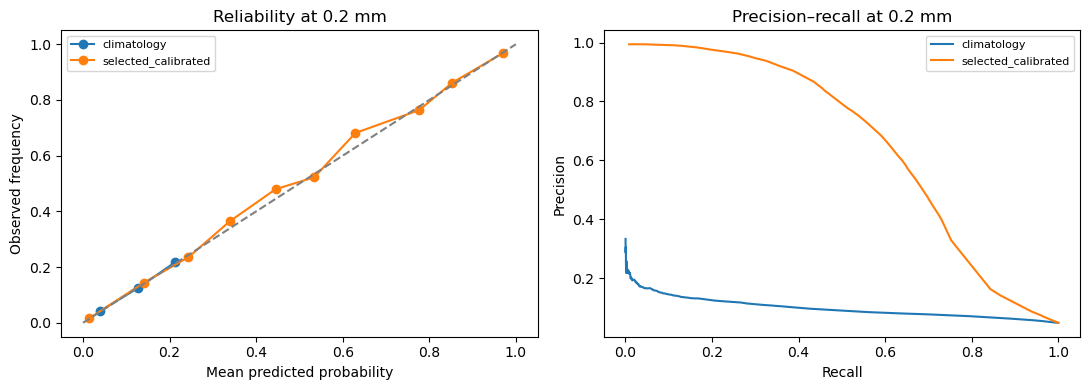

Metrics and scores saved under gs://sg-rainfall-dsa5208-261011-data/runs/20261012-full-02/results
Figure saved to gs://sg-rainfall-dsa5208-261011-data/runs/20261012-full-02/figures/task2/final_holdout_model_comparison.png
Download both task figure folders from the local repository root:
gcloud storage cp --recursive gs://sg-rainfall-dsa5208-261011-data/runs/20261012-full-02/figures ./report/figures/


In [41]:
primary_threshold = primary_thresholds[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for row in evaluation_rows:
    name = row["model"]
    scores = test_scores[name]
    at_threshold = scores.where(F.col("threshold_mm") == primary_threshold)
    reliability = reliability_table(at_threshold).orderBy("bin").toPandas()
    axes[0].plot(
        reliability["predicted_probability"],
        reliability["observed_frequency"],
        marker="o",
        label=name,
    )
    curve = precision_recall_points(at_threshold)
    axes[1].plot(curve["recall"], curve["precision"], label=name)

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(xlabel="Mean predicted probability", ylabel="Observed frequency")
axes[0].set_title(f"Reliability at {primary_threshold:g} mm")
axes[1].set(xlabel="Recall", ylabel="Precision")
axes[1].set_title(f"Precision–recall at {primary_threshold:g} mm")
for axis in axes:
    axis.legend(fontsize=8)
figure_local_dir = (
    Path(tempfile.gettempdir()) / "dsa5208-rainfall" / RUN_ID / "task2"
)
figure_local_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_local_dir / "final_holdout_model_comparison.png"
figure_gcs_path = f"{ROOT}/figures/task2/{figure_path.name}"
fig.tight_layout()
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
upload = subprocess.run(
    ["gcloud", "storage", "cp", str(figure_path), figure_gcs_path],
    capture_output=True,
    text=True,
)
if upload.returncode:
    message = upload.stderr.strip() or "Could not upload the final holdout figure."
    raise RuntimeError(message)
print(f"Metrics and scores saved under {RESULTS_ROOT}")
print(f"Figure saved to {figure_gcs_path}")
print("Download both task figure folders from the local repository root:")
print(f"gcloud storage cp --recursive {ROOT}/figures ./report/figures/")

for frame in [pilot, train, selection, training_stations, test, *test_scores.values()]:
    frame.unpersist()
